# SAM-6D Usage Example

This notebook walks through the full SAM-6D pipeline using the `SAM6D` class in `src/sam6d.py`.

**Pipeline at a glance:**
1. **Init** — loads SAM + DINOv2 (ISM) and a ViT pose estimation model (PEM), renders CAD templates with BlenderProc, computes reference descriptors
2. **Forward** — given an RGBD frame (RGB image, depth map, camera intrinsics), returns 6DoF poses (R, t), proposal masks, and per-stage confidence scores

Rendered templates and descriptors are cached to `template_dir`, so subsequent runs skip the rendering and embedding steps.

In [1]:
import sys
sys.path.insert(0, "..")  # add repo root if running from a subdirectory

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

from src.sam6d import SAM6D

/home/joon/.virtualenvs/torch_obj_tracking/lib/python3.12/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## 1. Configuration

Point `CAD_PATH` at your object's CAD file (`.ply`, `.stl`, `.obj`, etc.).

Checkpoint weights are auto-downloaded on first run if not already present.

**Camera intrinsics** are read directly from the RealSense camera at startup — no manual K matrix needed.

**Depth convention:** the RealSense depth stream is in **millimetres** (z16 = uint16 mm), so `depth_scale` stays `1.0`.

In [2]:
FX, FY, CX, CY = 604.7352294921875, 604.958984375, 430.3172302246094, 245.13461303710938
K = np.array([
    [FX,  0,  CX],
    [0,  FY,  CY],
    [0,   0,   1],
], dtype=np.float32)

In [6]:
import pyrealsense2 as rs
import numpy as np
import time

SERIAL_NUMBER = '243322070950'
WIDTH = 640
HEIGHT = 480
FPS = 30
DEPTH_EXPOSURE_US = 6000
LASER_POWER_FRAC = 0.5
DEPTH_MIN_M = 0.0 # 0 min
DEPTH_MAX_M = 0.5 # 16 max
# ACCURACY = 1 # not supported
# MOTION_RANGE = 1 # not supported
DEPTH_GAIN = 16 # intel recommends keeping this at the lowest value for depth accuracy
COLOR_EXPOSURE_US = 166//2    # tune: lower = darker/sharper motion, higher = brighter
COLOR_WHITE_BALANCE_K = 4600  # tune: ~2800 warm, ~4600 neutral, ~6500 cool
DISPARITY_SHIFT = 50

CAMERA_AVAILABLE = False

try:
    # ------------------------------------------------------------------ #
    # Step 1: detect device — retry a few times in case USB is still       #
    #         settling after the previous kernel run.                      #
    # ------------------------------------------------------------------ #
    MAX_RETRIES = 5
    RETRY_DELAY_S = 1.0

    ctx = rs.context()
    for attempt in range(MAX_RETRIES):
        devices = ctx.query_devices()
        if len(devices) > 0:
            break
        print(f"[Camera] No device yet (attempt {attempt+1}/{MAX_RETRIES}), retrying in {RETRY_DELAY_S:.0f}s...")
        time.sleep(RETRY_DELAY_S)
    else:
        raise RuntimeError(
            "[Camera] No RealSense devices detected after retries. "
            "Check USB connection and that Terminal has Camera permission "
            "(System Settings → Privacy & Security → Camera)."
        )

    # ------------------------------------------------------------------ #
    # Step 2: hardware-reset to clear any stuck pipeline from a previous   #
    #         kernel run that was killed without calling rs_pipeline.stop() #
    # ------------------------------------------------------------------ #
    print("[Camera] Resetting device to clear any previous pipeline state...")
    devices[0].hardware_reset()
    time.sleep(3.0)  # wait for USB re-enumeration after reset

    # Re-query with a fresh context — the old one holds stale handles.
    ctx = rs.context()
    for attempt in range(MAX_RETRIES):
        devices = ctx.query_devices()
        if len(devices) > 0:
            break
        print(f"[Camera] Waiting for device after reset (attempt {attempt+1}/{MAX_RETRIES})...")
        time.sleep(RETRY_DELAY_S)
    else:
        raise RuntimeError("[Camera] Device did not re-appear after hardware reset.")

    print(f"[Camera] Device ready: {devices[0].get_info(rs.camera_info.name)}")

    # ------------------------------------------------------------------ #
    # Step 3: normal pipeline init                                         #
    # ------------------------------------------------------------------ #
    rs_pipeline = rs.pipeline()
    rs_config = rs.config()

    rs_config.enable_device(SERIAL_NUMBER)
    rs_config.enable_stream(rs.stream.depth, WIDTH, HEIGHT, rs.format.z16, FPS)
    rs_config.enable_stream(rs.stream.color, WIDTH, HEIGHT, rs.format.rgb8, FPS)

    rs_profile = rs_pipeline.start(rs_config)

    # ==========================================
    # DISPARITY SHIFT (ADVANCED MODE)
    # ==========================================
    device = rs_profile.get_device()
    advanced_mode = rs.rs400_advanced_mode(device)

    if advanced_mode.is_enabled():
        print(f"Advanced mode is active. Setting disparity shift to {DISPARITY_SHIFT}...")
        depth_table = advanced_mode.get_depth_table()
        depth_table.disparityShift = DISPARITY_SHIFT 
        advanced_mode.set_depth_table(depth_table)
    else:
        print("Advanced mode is NOT enabled on this device. Disparity shift skipped.")
    # ==========================================

    rs_align = rs.align(rs.stream.color) 

    # Depth sensor
    depth_sensor = rs_profile.get_device().first_depth_sensor()
    depth_scale = depth_sensor.get_depth_scale()

    depth_sensor.set_option(rs.option.emitter_enabled, 1) 

    # depth exposure 
    if depth_sensor.supports(rs.option.enable_auto_exposure):
        print('Auto exposure supported.')
        depth_sensor.set_option(rs.option.enable_auto_exposure, 0)

    if depth_sensor.supports(rs.option.exposure):
        print('Exposure supported.')
        depth_sensor.set_option(rs.option.exposure, DEPTH_EXPOSURE_US)

    # depth gain
    if depth_sensor.supports(rs.option.gain):
        print('Gain supported.')
        depth_sensor.set_option(rs.option.gain, DEPTH_GAIN)

    # laser power 
    if depth_sensor.supports(rs.option.laser_power):
        print('Laser power supported.')
        laser_range = depth_sensor.get_option_range(rs.option.laser_power)
        laser_power = laser_range.min + LASER_POWER_FRAC * (laser_range.max - laser_range.min)
        print(laser_power)
        depth_sensor.set_option(rs.option.laser_power, laser_power)

    # Color sensor — lock exposure and white balance for consistent color across frames
    color_sensor = rs_profile.get_device().first_color_sensor()

    if color_sensor.supports(rs.option.enable_auto_exposure):
        color_sensor.set_option(rs.option.enable_auto_exposure, 0)
        color_sensor.set_option(rs.option.exposure, COLOR_EXPOSURE_US)
        print(f'Color exposure locked at {COLOR_EXPOSURE_US} us')

    if color_sensor.supports(rs.option.enable_auto_white_balance):
        color_sensor.set_option(rs.option.enable_auto_white_balance, 0)
        color_sensor.set_option(rs.option.white_balance, COLOR_WHITE_BALANCE_K)
        print(f'Color white balance locked at {COLOR_WHITE_BALANCE_K} K')

    color_profile = rs_profile.get_stream(rs.stream.color)
    intr = color_profile.as_video_stream_profile().get_intrinsics()
    K = np.array([[intr.fx,       0, intr.ppx], 
                  [      0, intr.fy, intr.ppy],
                  [      0,       0,         1],], dtype=np.float32)
    print(K)

    # capture a rgbd frame
    frames = rs_pipeline.wait_for_frames(timeout_ms=5000)
    frames.keep()
    aligned = rs_align.process(frames)

    color_frame = aligned.get_color_frame()
    depth_frame = aligned.get_depth_frame()

    rgb = np.asanyarray(color_frame.get_data())
    depth_raw = np.asanyarray(depth_frame.get_data())
    depth = depth_raw.astype(np.float32) * depth_scale

    rs_pipeline.stop()
    CAMERA_AVAILABLE = True

except Exception as e:
    print(f"[Camera] Failed — {e}")


[Camera] Resetting device to clear any previous pipeline state...
[Camera] Device ready: Intel RealSense D435IF
Advanced mode is active. Setting disparity shift to 50...
Auto exposure supported.
Exposure supported.
Gain supported.
Laser power supported.
180.0
Color exposure locked at 83 us
Color white balance locked at 4600 K
[[604.73535   0.      326.31726]
 [  0.      604.959   245.13461]
 [  0.        0.        1.     ]]


In [7]:
# --- Paths --- adjust these to your setup
CAD_PATH     = "/home/joon/Downloads/cad_files/steering_knuckle/steering-knuckle-thunder-truck-r1-r.stl"
TEMPLATE_DIR = "./sam6d_templates"   # rendered views + descriptors are cached here

# Camera intrinsic matrix (3x3) — replace with your actual camera K
# K = np.array([
#     [572.4114,   0.    , 325.2611],
#     [  0.    , 573.5704, 242.0490],
#     [  0.    ,   0.    ,   1.    ],
# ], dtype=np.float32)

DEPTH_SCALE = 1000.0   # multiply raw depth pixels → mm (1.0 if already mm)

# Optional: apply a solid color to colorless meshes (e.g. STL files without texture)
MESH_COLOR = (int(0.01*255), int(0.01*255), int(0.01*255))  # RGB 0-255, or None to leave as-is

# Optional: use flat shading so that flat faces render flat (helps for CAD/STL)
FLAT_SHADING = True

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Using device: cuda


## 2. Initialize SAM6D

Initialization renders 42 BlenderProc templates (skipped if already cached), computes ISM reference descriptors, and pre-extracts PEM template point-cloud features.

Key parameters:
- `sam_model_type`: `"vit_h"` (default, best quality ~2.4 GB), `"vit_l"` / `"vit_b"` (**~358 MB each — use these when VRAM is tight**)
- `n_template_view`: how many of the 42 rendered views PEM uses (42 = all, fewer = faster)
- `det_score_thresh`: ISM proposals below this score are dropped before pose estimation
- `confidence_thresh`: minimum DINOv2 semantic similarity to even consider a proposal
- `mesh_color`: RGB tuple (0–255) applied to colorless meshes (e.g. STL); `None` leaves textures as-is
- `flat_shading`: set `True` to disable normal interpolation so flat faces render flat
- `roughness`: Principled BSDF roughness — `0.0` = mirror/glossy, `1.0` = fully matte (`None` = Blender default 0.5)
- `metallic`: Principled BSDF metallic weight — `0.0` = plastic, `1.0` = metallic conductor (`None` = Blender default 0.0)
- `light_energy`: point light brightness in watts (default `1000`)
- `min_component_area_ratio`: drop disconnected mask blobs smaller than this fraction of the largest blob (0 = off)
- `mask_overlap_thresh`: suppress the lower-scoring detection when two masks overlap by more than this fraction of the smaller mask's area (0 = off)

**Memory management options** (all default `False`):
- `half_precision`: load SAM, DINOv2, and PEM in **fp16** — cuts weight VRAM ~50% (~2.5 GB saved); slight accuracy risk
- `auto_offload`: automatically move all models to CPU after each `forward()` call, freeing ~5 GB before FoundationPose runs; call `reload_to_gpu()` before the next forward
- `empty_cache_between_stages`: call `torch.cuda.empty_cache()` after SAM, DINOv2, and PEM stages to return fragmented buffers to the allocator

In [8]:
model = SAM6D(
    cad_path=CAD_PATH,
    device=DEVICE,

    # Segmentor
    # sam_model_type="vit_b",  # "vit_b" / "vit_l" use ~358 MB vs "vit_h" at 2.4 GB
    sam_model_type="vit_h",
    stability_score_thresh=0.97,

    # Template rendering
    blender_path='/home/joon/blender/blender-arm64',
    template_dir=TEMPLATE_DIR,
    reset_templates=False,   # set True to force re-render
    mesh_color=MESH_COLOR,   # RGB (0-255) for colorless meshes, or None
    flat_shading=FLAT_SHADING,  # True = flat faces render flat
    roughness=0.9,              # 0.0 = mirror/glossy, 1.0 = fully matte
    metallic=0.0,               # 0.0 = plastic/dielectric, 1.0 = metallic
    light_energy=1100,          # point light brightness in watts

    # Matching / filtering
    det_score_thresh=0.35,   # minimum combined ISM score: (semantic + appearance + geometric×visible_ratio) / (2 + visible_ratio)
    confidence_thresh=0.25,  # minimum DINOv2 CLS-token semantic similarity; proposals below this are discarded before appearance/geometric scoring runs
    visible_thred=0.5,
    n_template_view=42,
    min_component_area_ratio=0.005,  # drop disconnected mask blobs < 0.5% of largest
    mask_overlap_thresh=0.9,         # suppress lower-scoring mask if overlap > 90%
    geo_iou_thresh=0.0,              # drop proposals with geometric IoU below this (0=off)
    pose_score_thresh=0.3,           # drop detections with pose score below this (0=off)

    # Memory management — uncomment to reduce VRAM usage
    half_precision=False,             # fp16 weights: ~50% less VRAM, slight accuracy risk
    # auto_offload=True,               # free ~5 GB after each forward(); reload with model.reload_to_gpu()
    # empty_cache_between_stages=True, # torch.cuda.empty_cache() between SAM / DINOv2 / PEM stages
)

load pre-trained checkpoint from: /home/joon/Projects/baseline-sam6D-foundation-pose/checkpoints/mae_pretrain_vit_base.pth


## 3. Load RGBD Data

Replace the paths below with your actual RGB image and depth map.
The depth map should be a single-channel image (uint16 or float) with values in mm.

In [10]:
# --- Load from file (run this cell if no RealSense camera is available) ---
# Set rgb, depth, K, and depth_scale from a saved pickle or other file.
# Uncomment and fill in the path below, then run this cell.

# import pickle
# with open('/path/to/your/rgbd.pkl', 'rb') as f:
#     loaded_data = pickle.load(f)
# rgb   = loaded_data[0]   # (H, W, 3) uint8
# depth = loaded_data[1]   # (H, W) float32, units matching DEPTH_SCALE
# # K is already set from cell 27787368 — override here if needed
# # depth_scale is already set to DEPTH_SCALE — override here if needed

# print(f"RGB shape:   {rgb.shape}")
# print(f"Depth shape: {depth.shape}")
# print(f"Depth range: {depth.min():.1f} – {depth.max():.1f}")


## 4. Run Forward Pass

`forward()` accepts an RGB array/PIL image, a depth map (mm), and camera intrinsics, and returns a dict with poses and all intermediate scores.

In [11]:
results = model(rgb, depth, K, depth_scale=DEPTH_SCALE)   # or model.forward(...)

N = len(results["poses"])
print(f"Detections passing threshold: {N}")
print()
print(f"masks:             {results['masks'].shape}         # [N, H, W] bool")
print(f"boxes:             {results['boxes'].shape}         # [N, 4] xyxy")
print(f"ism_scores:        {results['ism_scores'].shape}    # [N] final ISM confidence")
print(f"semantic_scores:   {results['semantic_scores'].shape}")
print(f"appe_scores:       {results['appe_scores'].shape}")
print(f"geometric_scores:  {results['geometric_scores'].shape}")
print(f"pred_R:            {results['pred_R'].shape}        # [N, 3, 3]")
print(f"pred_t:            {results['pred_t'].shape}        # [N, 3]  (mm)")
print(f"pose_scores:       {results['pose_scores'].shape}")

if N > 0:
    best = np.argmax(results['pose_scores'])
    print(f"\nBest pose (detection {best}, score={results['pose_scores'][best]:.3f}):")
    print(f"  R =\n{results['pred_R'][best]}")
    print(f"  t = {results['pred_t'][best]} mm")

Detections passing threshold: 2

masks:             (2, 480, 640)         # [N, H, W] bool
boxes:             (2, 4)         # [N, 4] xyxy
ism_scores:        (2,)    # [N] final ISM confidence
semantic_scores:   (2,)
appe_scores:       (2,)
geometric_scores:  (2,)
pred_R:            (2, 3, 3)        # [N, 3, 3]
pred_t:            (2, 3)        # [N, 3]  (mm)
pose_scores:       (2,)

Best pose (detection 1, score=0.523):
  R =
[[ 0.20619905  0.79422975  0.5715614 ]
 [ 0.36023796 -0.6047052   0.71032447]
 [ 0.9097862   0.05943084 -0.41080123]]
  t = [-358.95328  214.94377  221.10965] mm


## 5. Memory Management Before FoundationPose

SAM6D holds ~5 GB of VRAM persistently (SAM ViT-H 2.4 GB + DINOv2 1.2 GB + PEM 1.3 GB). Since SAM6D and FoundationPose run sequentially, you can reclaim that memory before FoundationPose starts.

**Option A — automatic** (`auto_offload=True` at init time):
```python
model = SAM6D(..., auto_offload=True)
results = model(rgb, depth, K)   # models offloaded to CPU automatically on return
fp_results = fp(rgb, depth, K, results)
model.reload_to_gpu()            # bring models back before the next forward()
```

**Option B — manual control** (call explicitly when you need it):
```python
results = model(rgb, depth, K)
model.offload_to_cpu()           # ~5 GB freed immediately
fp_results = fp(rgb, depth, K, results)
model.reload_to_gpu()            # reload before next frame
```

The cell below shows how to measure the VRAM freed.

In [12]:
before_mb = torch.cuda.memory_allocated() / 1024**2
print(f"VRAM before offload: {before_mb:.0f} MB")

model.offload_to_cpu()

after_mb = torch.cuda.memory_allocated() / 1024**2
print(f"VRAM after  offload: {after_mb:.0f} MB  ({before_mb - after_mb:.0f} MB freed)")

# FoundationPose can now use the freed memory.
# Uncomment to reload SAM6D models before the next forward():
# model.reload_to_gpu()

VRAM before offload: 8294 MB
VRAM after  offload: 4167 MB  (4126 MB freed)


## 5. Visualize Detections

Each detection is shown with its ISM mask overlay and bounding box. The best-scoring pose is highlighted.

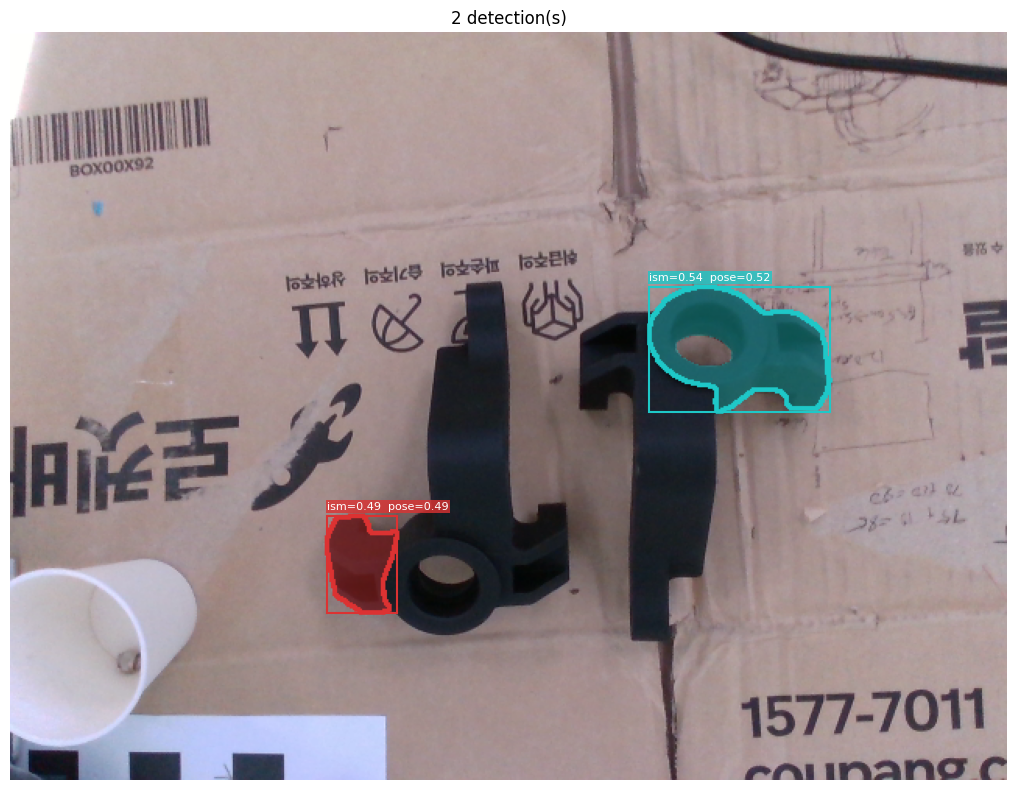

In [13]:
def visualize_detections(rgb, results, alpha=0.4):
    import cv2

    COLORS = [
        "#DC3232", "#1EC8C8", "#3264DC", "#32B432",
        "#A032DC", "#F08C1E", "#E650B4", "#C8C828",
    ]

    def hex_to_rgb(h):
        h = h.lstrip("#")
        return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)])

    masks       = results["masks"]       # [N, H, W] bool
    boxes       = results["boxes"]       # [N, 4] xyxy
    ism_scores  = results["ism_scores"]
    pose_scores = results["pose_scores"]

    if len(masks) == 0:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(rgb)
        ax.set_title("No detections")
        ax.axis("off")
        plt.show()
        return

    colors = [hex_to_rgb(COLORS[i % len(COLORS)]) for i in range(len(masks))]

    order   = np.argsort([-m.sum() for m in masks])
    overlay = rgb.copy().astype(float)
    for i in order:
        mask = masks[i].astype(bool)
        overlay[mask] = (1 - alpha) * overlay[mask] + alpha * colors[i]

    canvas = overlay.astype(np.uint8)
    for i in order:
        contours, _ = cv2.findContours(
            masks[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(canvas, contours, -1, colors[i].tolist(), 2)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(canvas)

    for i, (box, ism_s, pose_s) in enumerate(zip(boxes, ism_scores, pose_scores)):
        x1, y1, x2, y2 = box
        color = colors[i] / 255.0
        lw = 1.5
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=lw, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        label = f"ism={ism_s:.2f}  pose={pose_s:.2f}"
        ax.text(
            x1, y1 - 4, label,
            color="white", fontsize=8,
            bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"),
        )

    ax.axis("off")
    ax.set_title(f"{len(masks)} detection(s)")
    plt.tight_layout()
    plt.show()


visualize_detections(rgb, results)

## 6. Project Poses onto Image

All detections are overlaid on the image with their CAD point cloud and coordinate axes.
The **best-scoring** detection uses orange dots and thick axes; others use grey dots and thin axes.

Axes convention: **X = blue**, **Y = green**, **Z = red** (OpenCV camera frame).
Adjust `axis_len_mm` to match your object's scale.

Mesh extents (raw units): [31.3474884  43.34884644 35.        ]
  → after mesh_unit_to_mm=2.75: [ 86.20559311 119.2093277   96.25      ] mm
Pose t[0] (mm): [198.14822  244.19106  -25.191343]  (z should ≈ depth in mm)


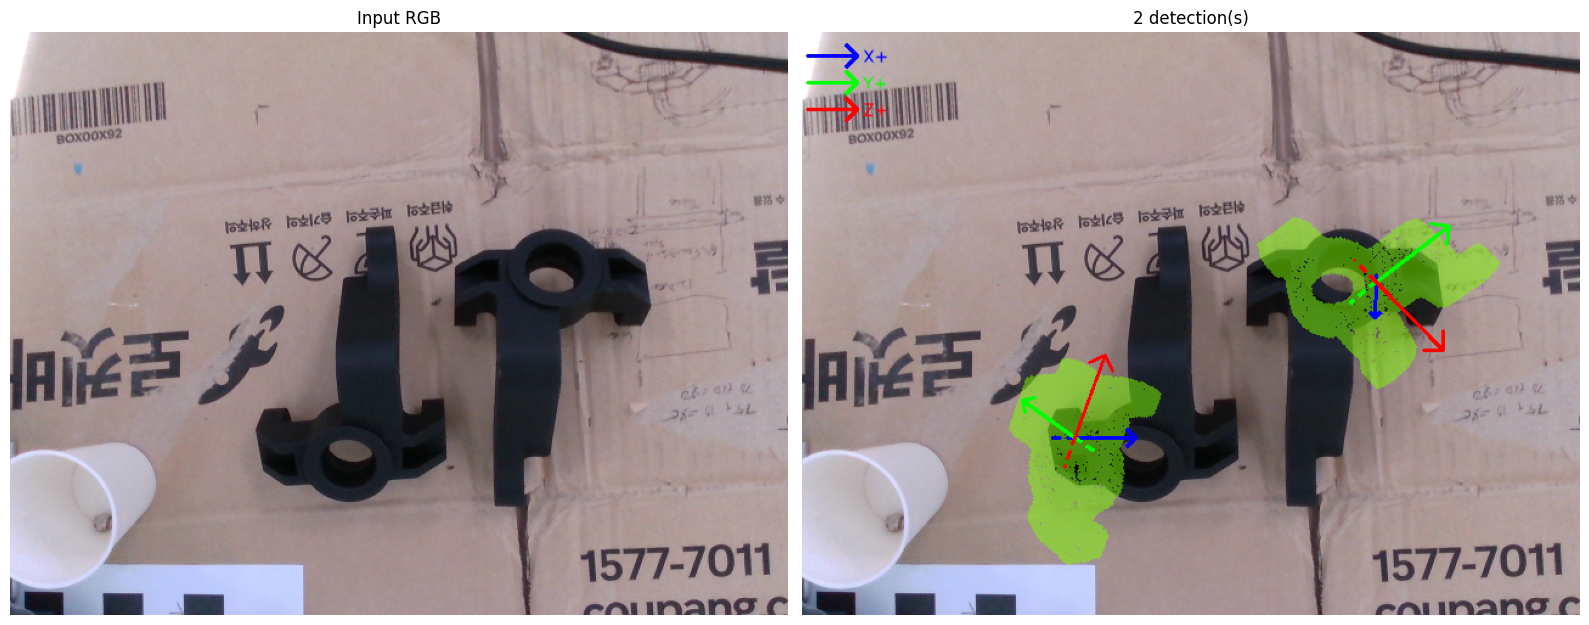

In [14]:
def project_all_poses(rgb, results, K, cad_path, n_pts=1024, axis_len_mm=10, mesh_unit_to_mm=1.0):
    import trimesh, cv2

    poses       = results['poses']
    pose_scores = results['pose_scores']
    if len(poses) == 0:
        print('No detections — nothing to project.')
        return

    mesh    = trimesh.load_mesh(cad_path)
    pts_raw = mesh.sample(n_pts).astype(np.float32)
    centroid_raw = mesh.centroid.astype(np.float32)

    print(f"Mesh extents (raw units): {mesh.extents}")
    print(f"  → after mesh_unit_to_mm={mesh_unit_to_mm}: {mesh.extents * mesh_unit_to_mm} mm")
    if results['poses']:
        print(f"Pose t[0] (mm): {results['poses'][0]['t']}  (z should ≈ depth in mm)")

    # Scale the point cloud around the mesh centroid (not the camera origin).
    # t already encodes R @ centroid_raw, so the centroid projects to the correct
    # image location regardless of mesh_unit_to_mm — only the spread changes.
    pts_mm = centroid_raw + (pts_raw - centroid_raw) * mesh_unit_to_mm

    best_i = int(np.argmax(pose_scores))
    # Axis origin: mesh centroid in object space. R @ centroid_raw + t = ref_centroid_mm.
    origin = centroid_raw

    fx, fy, cx, cy = K[0,0], K[1,1], K[0,2], K[1,2]
    H, W = rgb.shape[:2]

    def project(pts_cam):
        u = (pts_cam[:, 0] * fx / pts_cam[:, 2] + cx).astype(int)
        v = (pts_cam[:, 1] * fy / pts_cam[:, 2] + cy).astype(int)
        valid = (u >= 0) & (u < W) & (v >= 0) & (v < H) & (pts_cam[:, 2] > 0)
        return u, v, valid

    def pt2img(p_obj, R, t_mm):
        p_cam = R @ p_obj + t_mm
        if p_cam[2] <= 0:
            return None
        return (int(p_cam[0] * fx / p_cam[2] + cx),
                int(p_cam[1] * fy / p_cam[2] + cy))

    def draw_dashed_line(img, p1, p2, color, thickness=1, gap=6):
        """Draw a dashed line from p1 to p2."""
        dx, dy = p2[0] - p1[0], p2[1] - p1[1]
        dist = max(1, int((dx**2 + dy**2) ** 0.5))
        for i in range(0, dist, gap * 2):
            t0, t1 = i / dist, min((i + gap) / dist, 1.0)
            a = (int(p1[0] + t0 * dx), int(p1[1] + t0 * dy))
            b = (int(p1[0] + t1 * dx), int(p1[1] + t1 * dy))
            cv2.line(img, a, b, color, thickness)

    canvas = rgb.copy()
    overlay = canvas.copy()

    # --- point cloud ---
    for idx, pose in enumerate(poses):
        R, t = pose['R'], pose['t']
        pts_cam = (R @ pts_mm.T).T + t[None, :]
        u, v, valid = project(pts_cam)
        dot_color = (255 // 2, 255, 0)
        for ui, vi in zip(u[valid], v[valid]):
            cv2.circle(overlay, (ui, vi), 1, dot_color, -1)

    canvas = cv2.addWeighted(canvas, 0.5, overlay, 0.5, 0)

    # --- axes ---
    AXIS_COLORS = [(0, 0, 255), (0, 255, 0), (255, 0, 0)]  # X=blue, Y=green, Z=red
    NEG_LEN = 0.35   # negative stub = 35% of axis_len_mm

    for idx, pose in enumerate(poses):
        R, t = pose['R'], pose['t']
        o_img = pt2img(origin, R, t)
        if o_img is None:
            continue
        thickness = 2

        for axis_idx, color in enumerate(AXIS_COLORS):
            unit = np.zeros(3); unit[axis_idx] = 1.0

            # positive direction: solid arrow
            tip = pt2img(origin + unit * axis_len_mm, R, t)
            if tip is not None:
                cv2.arrowedLine(canvas, o_img, tip, color, thickness, tipLength=0.2)

            # negative direction: dashed stub so you can read +/- orientation
            neg_tip = pt2img(origin - unit * axis_len_mm * NEG_LEN, R, t)
            if neg_tip is not None:
                draw_dashed_line(canvas, o_img, neg_tip, color, thickness)

    # --- legend ---
    for i, (lbl, color) in enumerate([("X+", (0,0,255)), ("Y+", (0,255,0)), ("Z+", (255,0,0))]):
        y = 20 + i * 22
        cv2.arrowedLine(canvas, (10, y), (45, y), color, 2, tipLength=0.35)
        draw_dashed_line(canvas, (10, y), (2, y), color, 2)  # neg stub sample
        cv2.putText(canvas, lbl, (50, y + 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(rgb)
    axes[0].set_title("Input RGB")
    axes[0].axis("off")
    axes[1].imshow(canvas)
    axes[1].set_title(
        f"{len(poses)} detection(s)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


project_all_poses(rgb, results, K, CAD_PATH, n_pts=4096*4, axis_len_mm=50, mesh_unit_to_mm=2.75)


## 7. Inspect Intermediate Score Distributions

SAM-6D's ISM computes three complementary scores per proposal before passing to PEM:
- **Semantic** — DINOv2 CLS-token cosine similarity to reference templates
- **Appearance** — masked patch-token similarity (texture/appearance)
- **Geometric** — IoU between projected template point cloud and proposal bbox (depth-aware)

Inspecting these independently is useful for diagnosing failures.

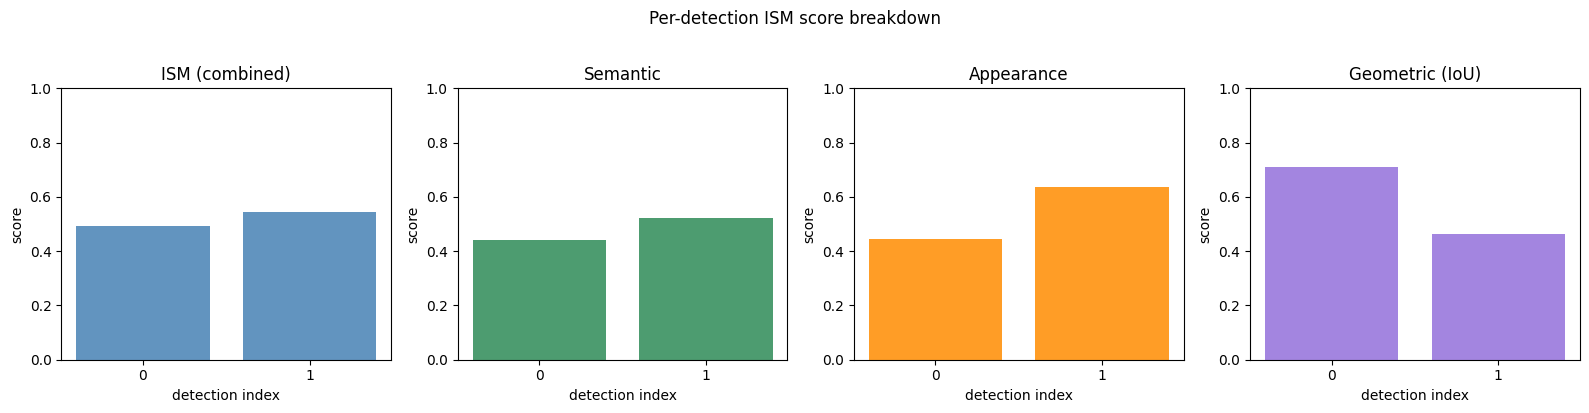

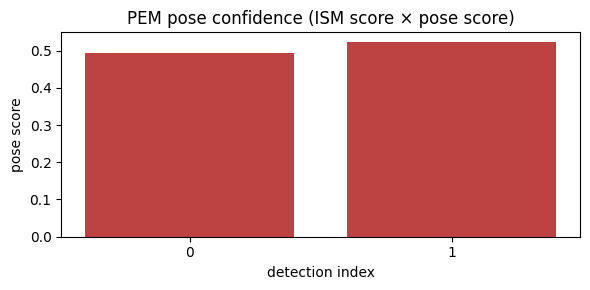

In [15]:
if len(results["ism_scores"]) > 0:
    N = len(results["ism_scores"])
    det_ids = np.arange(N)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)

    score_data = [
        ("ISM (combined)",  results["ism_scores"],       "steelblue"),
        ("Semantic",        results["semantic_scores"],  "seagreen"),
        ("Appearance",      results["appe_scores"],      "darkorange"),
        ("Geometric (IoU)", results["geometric_scores"], "mediumpurple"),
    ]

    for ax, (title, vals, color) in zip(axes, score_data):
        ax.bar(det_ids, vals, color=color, alpha=0.85)
        ax.set_title(title)
        ax.set_xlabel("detection index")
        ax.set_ylabel("score")
        ax.set_xticks(det_ids)
        ax.set_ylim(0, 1)

    plt.suptitle("Per-detection ISM score breakdown", y=1.02)
    plt.tight_layout()
    plt.show()

    # PEM confidence
    fig, ax = plt.subplots(figsize=(max(6, N * 0.8), 3))
    ax.bar(det_ids, results["pose_scores"], color="firebrick", alpha=0.85)
    ax.set_title("PEM pose confidence (ISM score × pose score)")
    ax.set_xlabel("detection index")
    ax.set_ylabel("pose score")
    ax.set_xticks(det_ids)
    plt.tight_layout()
    plt.show()
else:
    print("No detections to display.")

## 8. FoundationPose Pose Refinement

[FoundationPose](https://github.com/NVlabs/FoundationPose) refines the initial SAM-6D pose estimates using iterative RGB-D re-rendering and a learned score network. It operates in two modes:

- **Registration** (`refine_from_sam6d` / `__call__`) — given a new frame with SAM-6D detections, registers FoundationPose on each detection's mask and returns a refined 4×4 pose matrix (translation in **metres**).
- **Tracking** (`track`) — on subsequent frames, tracks each registered object without re-running SAM-6D.

**Prerequisites before running:**
1. Build the `mycpp` C++ extension (needed for pose hypothesis clustering):
   ```bash
   cd FoundationPose-main/mycpp && mkdir -p build && cd build \
     && cmake .. -DPYTHON_EXECUTABLE=$(which python) && make -j4
   ```
2. Model weights (~300 MB) are auto-downloaded from Google Drive on first run into `FoundationPose-main/weights/`. To download manually, see `FoundationPose-main/readme.md`.

In [19]:
from src.foundationpose import FoundationPoseRefiner

fp = FoundationPoseRefiner(
    cad_path=CAD_PATH,
    device=DEVICE,

    # Mesh units → metres conversion (1/1000 = mm→m, which is the default for STL/CAD files)
    mesh_scale=1/1000.0,   # STL units → metres (1/1000 for mm STL)
    physical_scale=3,    # set >1 if physical object is larger than the CAD model

    # Refinement iterations: more = slower but more accurate
    est_refine_iter=5,    # for register() — first frame
    track_refine_iter=2,  # for track()    — subsequent frames

    # Detection filtering
    max_detections=4,   # None = refine all SAM-6D detections; int N = top-N by pose_score
    min_pose_score=0.0,    # skip SAM-6D detections with pose_score below this threshold

    debug=0,               # 0 = silent; ≥2 = saves debug renders to debug_dir

    # Memory management — uncomment to reduce VRAM usage
    # half_precision=True,  # fp16 weights for RefineNet + ScoreNet (~50% less VRAM)
    # lazy_load=True,       # defer loading RefineNet/ScoreNet until first refine_from_sam6d() call
)

[__init__()] Loading mesh from /home/joon/Downloads/cad_files/steering_knuckle/steering-knuckle-thunder-truck-r1-r.stl (mesh_scale=0.001, physical_scale=3) ...
[__init__()] Mesh loaded: 24785 vertices, diameter≈0.1300 m  (mesh_scale=0.001, physical_scale=3).
[_load_models()] Loading PoseRefinePredictor ...
[__init__()] welcome
[__init__()] self.cfg: 
 lr: 0.0001
c_in: 6
zfar: .inf
debug: null
w_rot: 0.1
n_view: 1
run_id: null
use_BN: true
rot_rep: axis_angle
ckpt_dir: /home/joon/Projects/baseline-sam6D-foundation-pose/FoundationPose-main/learning/training/../../weights/2023-10-28-18-33-37/model_best.pth
exp_name: 2023-10-28-18-33-37
save_dir: /tmp/2023-10-28-18-33-37/
loss_type: l2
optimizer: adam
trans_rep: tracknet
batch_size: 64
crop_ratio: 1.2
use_normal: false
BN_momentum: 0.1
max_num_key: null
warmup_step: -1
input_resize:
- 160
- 160
max_step_val: 1000
normal_uint8: false
vis_interval: 1000
weight_decay: 0
n_max_objects: null
normalize_xyz: true
clip_grad_norm: 'Infinity'
rot_no

In [20]:
# Pass SAM-6D results directly — FoundationPose registers on each detection's mask.
# `results` is the dict returned by the SAM6D forward pass above.
refined = fp(rgb, depth, K, results, depth_scale=DEPTH_SCALE)

print(f"Refined {len(refined)} detection(s)\n")
for i, r in enumerate(refined):
    print(
        f"[{i}]  detection_idx={r['detection_idx']}"
        f"  sam6d_score={r['sam6d_score']:.3f}"
        f"  fp_score={r['fp_score']:.4f}"
    )
    print(f"     pose (4×4, translation in metres):")
    print(f"     {r['pose']}")

[_load_models()] FoundationPose models loaded.
[reset_object()] self.diameter:0.1593119833752112, vox_size:0.007965599168760561
[reset_object()] self.pts:torch.Size([257, 3])
[reset_object()] reset done
[make_rotation_grid()] cam_in_obs:(42, 4, 4)
[make_rotation_grid()] rot_grid:(252, 4, 4)
[make_rotation_grid()] after cluster, rot_grid:(252, 4, 4)
[make_rotation_grid()] self.rot_grid: torch.Size([252, 4, 4])
[register()] Welcome
[register()] poses:(252, 4, 4)
[register()] after viewpoint, add_errs min:-1.0
[predict()] ob_in_cams:(252, 4, 4)
[predict()] self.cfg.use_normal:False
[predict()] trans_normalizer:[0.019999999552965164, 0.019999999552965164, 0.05000000074505806], rot_normalizer:0.3490658503988659
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done


num original candidates = 252
num of pose after clustering: 252


[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch(

num original candidates = 252
num of pose after clustering: 252


[predict()] ob_in_cams:(252, 4, 4)
[predict()] self.cfg.use_normal:False
[predict()] trans_normalizer:[0.019999999552965164, 0.019999999552965164, 0.05000000074505806], rot_normalizer:0.3490658503988659
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()

Refined 2 detection(s)

[0]  detection_idx=1  sam6d_score=0.523  fp_score=39.0312
     pose (4×4, translation in metres):
     [[ 5.1101748e-02 -2.6253907e-02 -9.9834818e-01  1.4680387e-01]
 [ 4.5623332e-01  8.8986027e-01 -4.8124279e-05 -1.5876681e+00]
 [ 8.8839167e-01 -4.5547727e-01  5.7451319e-02  6.7387241e-01]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  1.0000000e+00]]
[1]  detection_idx=0  sam6d_score=0.492  fp_score=36.7188
     pose (4×4, translation in metres):
     [[ 0.03535047 -0.08122239  0.99606895  0.02382948]
 [-0.40642723 -0.91171616 -0.05991988  1.6426052 ]
 [ 0.91299903 -0.4027115  -0.06524049  0.5955459 ]
 [ 0.          0.          0.          1.        ]]


### Visualize Refined Poses

Project the FoundationPose-refined 4×4 pose onto the image using the CAD point cloud and coordinate axes.

The pose matrix uses **metres** for translation. The visualization converts to metres internally.

Axes: **X = blue**, **Y = green**, **Z = red** (camera frame). Adjust `axis_len_m` to your object's scale.

Mesh extents (viz): 94.0 x 130.0 x 105.0 mm  (mesh_scale=0.003000)
  detection: 8192 / 8192 pts in frame,  t=[ 0.1468 -1.5877  0.6739]
  detection: 8192 / 8192 pts in frame,  t=[0.0238 1.6426 0.5955]


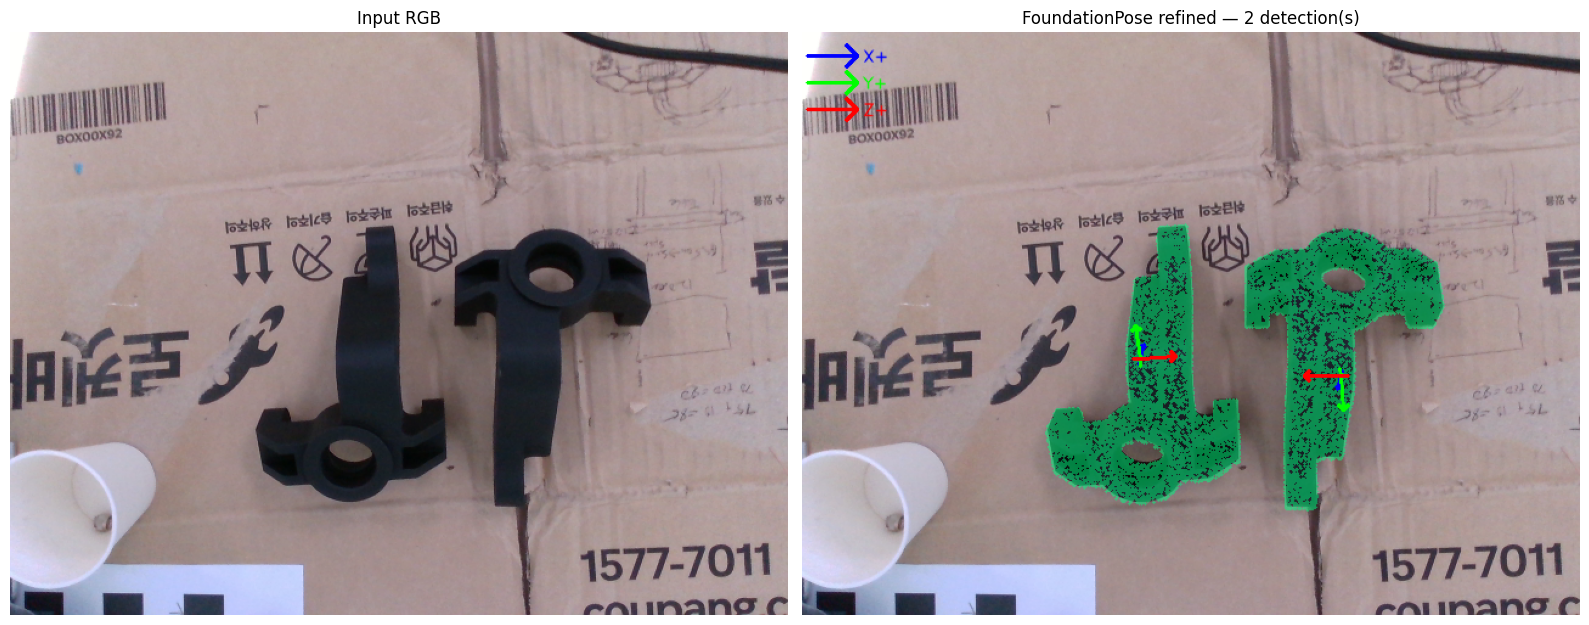

In [25]:
def project_fp_poses(rgb, refined_results, K, cad_path,
                     mesh_scale=1/1000.0,
                     n_pts=4096, axis_len_m=0.02):
    """Overlay FoundationPose refined poses on the image.

    Args:
        mesh_scale: Must equal fp.effective_scale (= FoundationPoseRefiner mesh_scale *
            physical_scale). This is the actual multiplier applied to mesh vertices before
            FoundationPose registered the pose, and must match exactly for the projection
            to be centred correctly. Do NOT use this to compensate for object size —
            set physical_scale in FoundationPoseRefiner instead and pass fp.effective_scale
            here.
        axis_len_m: Axis arrow length in metres (e.g. 0.02 = 20 mm).

    Math:
        FoundationPose returns pose T = [R | t_c - R @ c_m] where
        c_m = c_raw * effective_scale (FP's model_center). So for any point p_raw:
            p_cam = R @ (p_raw * effective_scale) + t = t_c + R @ (p_raw - c_raw) * effective_scale
        Using mesh_scale = effective_scale here makes c_m and pts_viz_m exactly match
        the frame FoundationPose used — axis origin projects to t_c (object centre). ✓
    """
    import trimesh, cv2

    if not refined_results:
        print("No refined poses to display.")
        return

    mesh = trimesh.load_mesh(cad_path)
    pts_raw = mesh.sample(n_pts).astype(np.float64)
    c_raw   = (mesh.bounds[0] + mesh.bounds[1]) / 2.0
    c_m     = c_raw * mesh_scale        # matches FP's model_center
    pts_viz_m = pts_raw * mesh_scale    # same frame FP used internally

    ext_mm = mesh.extents * mesh_scale * 1000
    print(f"Mesh extents (viz): {ext_mm[0]:.1f} x {ext_mm[1]:.1f} x {ext_mm[2]:.1f} mm"
          f"  (mesh_scale={mesh_scale:.6f})")

    fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
    H, W = rgb.shape[:2]

    def project_pt(p_obj_m, pose):
        p_cam = pose[:3, :3] @ p_obj_m + pose[:3, 3]
        if p_cam[2] <= 0:
            return None
        return (int(p_cam[0] * fx / p_cam[2] + cx),
                int(p_cam[1] * fy / p_cam[2] + cy))

    def draw_dashed_line(img, p1, p2, color, thickness=1, gap=6):
        dx, dy = p2[0] - p1[0], p2[1] - p1[1]
        dist = max(1, int((dx ** 2 + dy ** 2) ** 0.5))
        for k in range(0, dist, gap * 2):
            t0 = k / dist
            t1 = min((k + gap) / dist, 1.0)
            a = (int(p1[0] + t0 * dx), int(p1[1] + t0 * dy))
            b = (int(p1[0] + t1 * dx), int(p1[1] + t1 * dy))
            cv2.line(img, a, b, color, thickness)

    canvas = rgb.copy()
    overlay = canvas.copy()

    for r in refined_results:
        pose = r["pose"].astype(np.float64)
        pts_cam = (pose[:3, :3] @ pts_viz_m.T).T + pose[:3, 3]
        u = (pts_cam[:, 0] * fx / pts_cam[:, 2] + cx).astype(int)
        v = (pts_cam[:, 1] * fy / pts_cam[:, 2] + cy).astype(int)
        valid = (u >= 0) & (u < W) & (v >= 0) & (v < H) & (pts_cam[:, 2] > 0)
        print(f"  detection: {valid.sum()} / {len(u)} pts in frame,  "
              f"t={r['pose'][:3,3].round(4)}")
        for ui, vi in zip(u[valid], v[valid]):
            cv2.circle(overlay, (ui, vi), 1, (0, 255, 128), -1)

    canvas = cv2.addWeighted(canvas, 0.5, overlay, 0.5, 0)

    AXIS_COLORS = [(0, 0, 255), (0, 255, 0), (255, 0, 0)]  # X=blue, Y=green, Z=red
    NEG_RATIO = 0.35

    for r in refined_results:
        pose = r["pose"].astype(np.float64)
        o_img = project_pt(c_m, pose)
        if o_img is None:
            print(f"  WARNING: axis origin behind camera — t={pose[:3,3]}")
            continue
        for axis_idx, color in enumerate(AXIS_COLORS):
            unit = np.zeros(3)
            unit[axis_idx] = 1.0
            tip = project_pt(c_m + unit * axis_len_m, pose)
            if tip:
                cv2.arrowedLine(canvas, o_img, tip, color, 2, tipLength=0.2)
            neg = project_pt(c_m - unit * axis_len_m * NEG_RATIO, pose)
            if neg:
                draw_dashed_line(canvas, o_img, neg, color, 2)

    for i, (lbl, color) in enumerate([("X+", (0, 0, 255)), ("Y+", (0, 255, 0)), ("Z+", (255, 0, 0))]):
        y = 20 + i * 22
        cv2.arrowedLine(canvas, (10, y), (45, y), color, 2, tipLength=0.35)
        draw_dashed_line(canvas, (10, y), (2, y), color, 2)
        cv2.putText(canvas, lbl, (50, y + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(rgb)
    axes[0].set_title("Input RGB")
    axes[0].axis("off")
    axes[1].imshow(canvas)
    axes[1].set_title(f"FoundationPose refined — {len(refined_results)} detection(s)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


# mesh_scale = fp.effective_scale ensures the viz uses exactly the same scale
# that FoundationPose used during registration. To change the object scale,
# set physical_scale in FoundationPoseRefiner (cell above) and re-run registration.
project_fp_poses(rgb, refined, K, CAD_PATH,
                 mesh_scale=fp.effective_scale,
                 n_pts=4096*2, axis_len_m=0.02)

### Tracking on Subsequent Frames

After registration, call `fp.track()` on each new frame — no SAM-6D re-detection needed. Each active estimator independently tracks its registered object.

Call `fp.reset()` before processing a new scene or object.

In [ ]:
# --- Tracking demo ---
# Replace rgb2 / depth2 with your next-frame RGBD data.
# The estimator list from refine_from_sam6d() is retained in fp._est_list.

# rgb2   = ...   # (H, W, 3) uint8
# depth2 = ...   # (H, W) raw depth pixels

# tracked = fp.track(rgb2, depth2, K, depth_scale=DEPTH_SCALE)
# for i, t in enumerate(tracked):
#     print(f"[{i}] tracked pose:\n{t['pose']}")
#     project_fp_poses(rgb2, [{"pose": t["pose"]}], K, CAD_PATH, axis_len_m=0.02)

# --- Reset before a new scene ---
# fp.reset()

print("fp.track(rgb, depth, K, depth_scale=DEPTH_SCALE)  →  list of {pose} dicts, one per detection")
print("fp.reset()  →  clears stored estimators before a new scene")

fp.track(rgb, depth, K, depth_scale=DEPTH_SCALE)  →  list of {pose} dicts, one per detection
fp.reset()  →  clears stored estimators before a new scene
